# Reynolds-informative frequencies, Stage 1 residuals, and Stage 2 false alarms

**Research questions:** (1) Which Reynolds-informative channels have large Stage 1 errors? (2) Are signed errors associated with Reynolds level, ramp status, or experimental time? (3) Are those errors elevated **before** Stage 2 false alarms on verified healthy data?

**Design:** fixed evaluation run `1212_1`; pretrained Stage 1 and Stage 2 checkpoints, no retraining. The Stage 2 threshold must be declared (default 0.5 is a provisional diagnostic, not necessarily the operational tuned threshold). All analyses are observational. Adjacent windows overlap: descriptive statistics are not independent hypothesis tests. No causal claims. Run from `project_root/notebooks/` or `project_root/`.

In [1]:
from pathlib import Path
import re, json, warnings, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from IPython.display import display
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
# Set PROJECT_ROOT explicitly if your Jupyter server starts outside the project.
# Example: PROJECT_ROOT = Path('/home/ubuntu/notebooks/Leak_Detection')
PROJECT_ROOT = None

def find_project_root():
    if PROJECT_ROOT is not None:
        candidate = Path(PROJECT_ROOT).expanduser().resolve()
        if not ((candidate / 'data').is_dir() and (candidate / 'models').is_dir()):
            raise FileNotFoundError(f'PROJECT_ROOT does not contain data/ and models/: {candidate}')
        return candidate
    cwd = Path.cwd().resolve()
    candidates = []
    for parent in (cwd, *cwd.parents):
        candidates.extend((parent, parent / 'Leak_Detection', parent / 'leak_detection'))
        # A Jupyter server can be started in the parent of the project.
        if parent == cwd:
            candidates.extend(child for child in parent.iterdir() if child.is_dir())
    for candidate in dict.fromkeys(candidates):
        if (candidate / 'data' / '2026-03-04').is_dir() and (candidate / 'models').is_dir():
            return candidate
    raise FileNotFoundError(
        f'Could not locate project from Jupyter cwd={cwd}. '
        'Set PROJECT_ROOT above to the absolute path of the folder containing data/, models/, notebooks/, results/.'
    )

ROOT = find_project_root()
DATA_DIR=ROOT/'data'/'2026-03-04'; MODEL_DIR=ROOT/'models'; OUT=ROOT/'results'/'frequency_residual_stage2'; OUT.mkdir(parents=True,exist_ok=True)
assert DATA_DIR.is_dir(), f'Missing data folder: {DATA_DIR}'
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROBES=['UUS','US','DS','DDS']; W=40; S_SCALE=50.; RE_SCALE=150.
TRAIN_RUN='1211_1'; EVAL_RUN='1212_1'
# Supply checkpoint paths here if automatic discovery finds more than one candidate.
REVERSE_CHECKPOINT='models/compact_gru_e16_h24_1211_to_1212.pt'
FORWARD_CHECKPOINT='models/leak_detect_baseline.pt'
# Must be verified from source dataset; if None, auto-detect exact leak event columns, otherwise fail closed.
LEAK_COLUMN=None
# Forward model probe coordinates taken from original GTvate_leak_detect notebook, for these two runs.
COORDS={'1211_1':{'UUS':[-3.0226,.025],'US':[-.4572,.025],'DS':[.4572,.025],'DDS':[3.0226,.025]},
        '1212_1':{'UUS':[-4.1275,.025],'US':[-.4572,.025],'DS':[.4572,.025],'DDS':[1.9177,.025]}}
print('Project:',ROOT,'\nData:',DATA_DIR,'\nModels:',MODEL_DIR,'\nResults:',OUT)
print('Checkpoints:',*[str(p.relative_to(ROOT)) for p in MODEL_DIR.rglob('*.pt')],sep='\n  ')
STAGE2_CHECKPOINT='models/leak_detect_residual.pt'
STAGE2_THRESHOLD=0.50 # CHANGE to operational tuned threshold if known
PRE_ALARM_LOOKBACK=20 # endpoints preceding a false-alarm onset
RE_BINS=5


Project: /home/ubuntu/notebooks/Leak_Detection 
Data: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04 
Models: /home/ubuntu/notebooks/Leak_Detection/models 
Results: /home/ubuntu/notebooks/Leak_Detection/results/frequency_residual_stage2
Checkpoints:
  models/compact_gru_e16_h24_1211_to_1212.pt
  models/re_pred.pt
  models/leak_detect_baseline.pt
  models/compact_gru_e24_h16_1211_1_to_1212_1.pt
  models/leak_detect_residual.pt


## 1. Data and checkpoints
The original project CSVs and checkpoints are required. Verify leak flags, time alignment, and healthy-window definition. A false alarm is Stage 2 probability ≥ threshold on a truly healthy endpoint, **with a full healthy residual-input window**.

In [2]:
def frequency_cols(df):
    pairs=[]
    for c in df.columns:
        if 'ǀf' in str(c):
            try: pairs.append((float(str(c).split('ǀf',1)[1].replace('_','.')),c))
            except ValueError: pass
    pairs.sort()
    if len(pairs)!=27: raise ValueError(f'Expected 27 frequencies; found {len(pairs)}')
    return [f for f,c in pairs],[c for f,c in pairs]
def sensor_csv(path):
    if not path.exists(): raise FileNotFoundError(path)
    d=pd.read_csv(path,sep=None,engine='python').dropna(how='all').dropna(axis=1,how='all')
    if d.shape[1]==1: d=pd.read_csv(path,sep='\t')
    return d.reset_index(drop=True)
def find_col(d,kind):
    if kind=='time':
        matches=[c for c in d if 'date' in str(c).lower() and 'time' in str(c).lower()]
    else:
        matches=[c for c in d if 'reynolds' in str(c).lower()]
    if not matches: raise KeyError(f'No {kind} column in {list(d.columns)}')
    return matches[0]
def read_run(run):
    dfs={p:sensor_csv(DATA_DIR/f'{p}{run}.csv') for p in PROBES}
    lengths={p:len(d) for p,d in dfs.items()}
    if len(set(lengths.values()))!=1: raise ValueError(f'Probe row-count mismatch: {lengths}')
    f0=None; X=[]; ref=None
    for p,d in dfs.items():
        freqs,cols=frequency_cols(d)
        if f0 is None: f0=freqs
        elif not np.allclose(f0,freqs): raise ValueError(f'Frequency order mismatch on {p}')
        t=pd.to_datetime(d[find_col(d,'time')],errors='raise').to_numpy()
        re_=pd.to_numeric(d[find_col(d,'re')],errors='raise').to_numpy(float)
        if ref is None: ref=(t,re_)
        elif not (np.array_equal(ref[0],t) and np.allclose(ref[1],re_,rtol=0,atol=1e-4)):
            raise ValueError(f'Timestamps/Reynolds not aligned for {p}')
        X.append(d[cols].apply(pd.to_numeric,errors='raise').to_numpy(np.float32))
    d=dfs[PROBES[0]]
    candidates=[c for c in d if re.search(r'leak.?event|leak.?open|leak.?status',str(c),re.I)]
    chosen=LEAK_COLUMN
    if chosen is None:
        if len(candidates)!=1: raise ValueError(f'Cannot establish healthy windows. Leak column candidates: {candidates}; set LEAK_COLUMN to a verified column')
        chosen=candidates[0]
    if chosen not in d: raise KeyError(f'Leak column {chosen!r} absent')
    leak=pd.to_numeric(d[chosen],errors='raise').to_numpy()
    if not np.isfinite(leak).all(): raise ValueError('Missing leak flags')
    return dict(X=np.stack(X,axis=1),Re=ref[1].astype(np.float32),time=ref[0],leak=leak,freqs=np.asarray(f0),run=run,leak_column=chosen)
train=read_run(TRAIN_RUN); val=read_run(EVAL_RUN)
assert np.allclose(train['freqs'],val['freqs'])
def endpoints(run):
    t=np.arange(W-1,len(run['Re']))
    # reject windows with leak anywhere, not only at endpoint
    leak_count=np.convolve((run['leak']!=0).astype(int),np.ones(W,dtype=int),'valid')
    return t[leak_count==0]
idx_train=endpoints(train); idx_val=endpoints(val)
if not len(idx_train) or not len(idx_val): raise ValueError('No healthy windows found')
print('Healthy windows: train',len(idx_train),'eval',len(idx_val),'leak column',val['leak_column'])
print('Frequency values:',val['freqs'])

Healthy windows: train 7567 eval 7567 leak column Leak Event
Frequency values: [   25.     31.5    40.     50.     63.     80.    100.    125.    160.
   200.    250.    315.    400.    500.    630.    800.   1000.   1250.
  1600.   2000.   2500.   3100.   4000.   5000.   6300.   8000.  10000. ]


In [3]:
class CompactSpectralGRU(nn.Module):
    def __init__(self,embed_dim,hidden_dim):
        super().__init__(); self.encoder=nn.Sequential(nn.Linear(27,embed_dim),nn.ReLU()); self.gru=nn.GRU(embed_dim,hidden_dim,batch_first=True); self.head=nn.Linear(hidden_dim,1)
    def forward(self,x):
        z=self.encoder(x).mean(dim=2); h,_=self.gru(z); return self.head(h[:,-1]).squeeze(-1)
class BaselineSpectralModel(nn.Module):
    def __init__(self,Freq=27,hidden_dim=64,re_feat_dim=16,coord_feat_dim=16):
        super().__init__(); self.Freq=Freq
        self.re_embed=nn.Sequential(nn.Linear(1,re_feat_dim),nn.ReLU())
        self.coord_embed=nn.Sequential(nn.Linear(2,coord_feat_dim),nn.ReLU())
        self.re_lstm=nn.LSTM(re_feat_dim+coord_feat_dim,hidden_dim,batch_first=True)
        self.re_to_spec=nn.Linear(hidden_dim,Freq)
    def forward(self,X_window,Re_window,coords):
        B,T,P,F=X_window.shape
        a=self.re_embed(Re_window[:,:,None,None].expand(-1,-1,P,1))
        c=self.coord_embed(coords[:,None].expand(-1,T,-1,-1))
        z=torch.cat([a,c],dim=-1).permute(0,2,1,3).reshape(B*P,T,-1)
        h,_=self.re_lstm(z)
        return {'baseline':self.re_to_spec(h.reshape(B,P,T,-1).permute(0,2,1,3))}
def choose_checkpoint(manual,pattern):
    if manual is not None:
        p=Path(manual); p=p if p.is_absolute() else ROOT/p
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    found=sorted(MODEL_DIR.rglob(pattern))
    if len(found)!=1: raise ValueError(f'Expected one {pattern} in {MODEL_DIR}; found {found}. Set explicit checkpoint path in config cell.')
    return found[0]
def safe_load(path):
    try: return torch.load(path,map_location='cpu',weights_only=True)
    except TypeError: return torch.load(path,map_location='cpu')
reverse_path=choose_checkpoint(REVERSE_CHECKPOINT,'compact_gru_e*_h*_*.pt')
ck=safe_load(reverse_path)
if not isinstance(ck,dict) or 'model_state_dict' not in ck: raise ValueError('Reverse checkpoint missing model_state_dict')
assert int(ck.get('window_size',W))==W and float(ck.get('spectrum_scale',S_SCALE))==S_SCALE and float(ck.get('reynolds_scale',RE_SCALE))==RE_SCALE
reverse=CompactSpectralGRU(int(ck['embed_dim']),int(ck['hidden_dim'])); reverse.load_state_dict(ck['model_state_dict'],strict=True); reverse=reverse.to(DEVICE).eval()
forward_path=choose_checkpoint(FORWARD_CHECKPOINT,'*baseline*.pt')
fck=safe_load(forward_path); fstate=fck.get('model_state_dict',fck.get('state_dict',fck)) if isinstance(fck,dict) else fck
if not isinstance(fstate,dict): raise ValueError('Unsupported forward checkpoint')
# infer dimensions from checkpoint; no guesses about hidden sizes
rfd=fstate['re_embed.0.weight'].shape[0]; cfd=fstate['coord_embed.0.weight'].shape[0]; hidden=fstate['re_lstm.weight_hh_l0'].shape[1]
forward=BaselineSpectralModel(27,hidden,rfd,cfd); forward.load_state_dict(fstate,strict=True); forward=forward.to(DEVICE).eval()
print('Loaded reverse:',reverse_path,'\nLoaded forward:',forward_path)

Loaded reverse: /home/ubuntu/notebooks/Leak_Detection/models/compact_gru_e16_h24_1211_to_1212.pt 
Loaded forward: /home/ubuntu/notebooks/Leak_Detection/models/leak_detect_baseline.pt


In [4]:
def batch_predict_reverse(run,indices,batch=256,replace=None):
    outputs=[]; X=run['X']/S_SCALE
    with torch.no_grad():
        for start in range(0,len(indices),batch):
            ids=indices[start:start+batch]
            windows=np.stack([X[t-W+1:t+1] for t in ids]).astype(np.float32)
            if replace is not None: windows=replace(windows,ids)
            outputs.append(reverse(torch.from_numpy(windows).to(DEVICE)).cpu().numpy()*RE_SCALE)
    return np.concatenate(outputs)
def batch_predict_forward(run,indices,batch=128):
    outputs=[]; X=run['X']/S_SCALE; Re=run['Re']/RE_SCALE
    coords=torch.tensor([COORDS[run['run']][p] for p in PROBES],dtype=torch.float32,device=DEVICE)
    with torch.no_grad():
        for start in range(0,len(indices),batch):
            ids=indices[start:start+batch]
            x=np.stack([X[t-W+1:t+1] for t in ids]); r=np.stack([Re[t-W+1:t+1] for t in ids])
            cs=coords.unsqueeze(0).expand(len(ids),-1,-1)
            out=forward(torch.from_numpy(x).to(DEVICE),torch.from_numpy(r).to(DEVICE),cs)['baseline']
            outputs.append(out[:,-1].cpu().numpy()*S_SCALE)
    return np.concatenate(outputs)
y_re=val['Re'][idx_val]; re_hat=batch_predict_reverse(val,idx_val)
actual=val['X'][idx_val]; predicted=batch_predict_forward(val,idx_val)
residual=actual-predicted
print('Healthy reverse MAE:',mean_absolute_error(y_re,re_hat),'R2:',r2_score(y_re,re_hat))
print('Healthy forward overall RMSE:',np.sqrt(np.mean(residual**2)),'mean signed bias:',np.mean(residual))
np.savez_compressed(OUT/'healthy_aligned_predictions.npz',endpoint_index=idx_val,Re=y_re,reverse_Re=re_hat,actual=actual,predicted=predicted,residual=residual,frequencies=val['freqs'])

Healthy reverse MAE: 9.84679889678955 R2: 0.9167409539222717
Healthy forward overall RMSE: 2.471307 mean signed bias: -0.041878548


## 2. Frequency importance × Stage 1 residual magnitude
Load reverse-GRU importance calculated in the prior bidirectional notebook. Importance = increase in reverse Reynolds MAE after disrupting a probe-frequency. It is **predictive**, not causal. The importance CSV must be generated on the same evaluation run. Stage 1 signed residual = measured − predicted; positive means underprediction.

,probe,frequency,n,signed_bias,MAE,RMSE,importance,importance_pct,error_pct,joint_score
30,US,50.0,7567,2.405956,3.696661,5.226653,1.819051,0.981481,0.981481,0.963306
32,US,80.0,7567,5.824451,5.889480,6.717865,1.321389,0.962963,0.990741,0.954047
28,US,31.5,7567,3.765194,4.118714,5.142095,0.882718,0.925926,0.972222,0.900206
84,DDS,50.0,7567,-0.169239,2.302123,3.161211,2.069898,0.990741,0.907407,0.899005
62,DS,160.0,7567,-2.503546,2.845979,3.649545,1.197274,0.953704,0.935185,0.891890
35,US,160.0,7567,0.799832,2.159412,2.935800,2.547912,1.000000,0.861111,0.861111
38,US,315.0,7567,-1.358158,2.576527,3.122196,0.715603,0.916667,0.888889,0.814815
31,US,63.0,7567,2.692898,3.217767,4.137846,0.077824,0.787037,0.953704,0.750600
92,DDS,315.0,7567,0.434555,1.624799,2.683910,0.567086,0.898148,0.814815,0.731824
86,DDS,80.0,7567,-0.318958,2.125414,2.723936,0.414361,0.861111,0.824074,0.709619


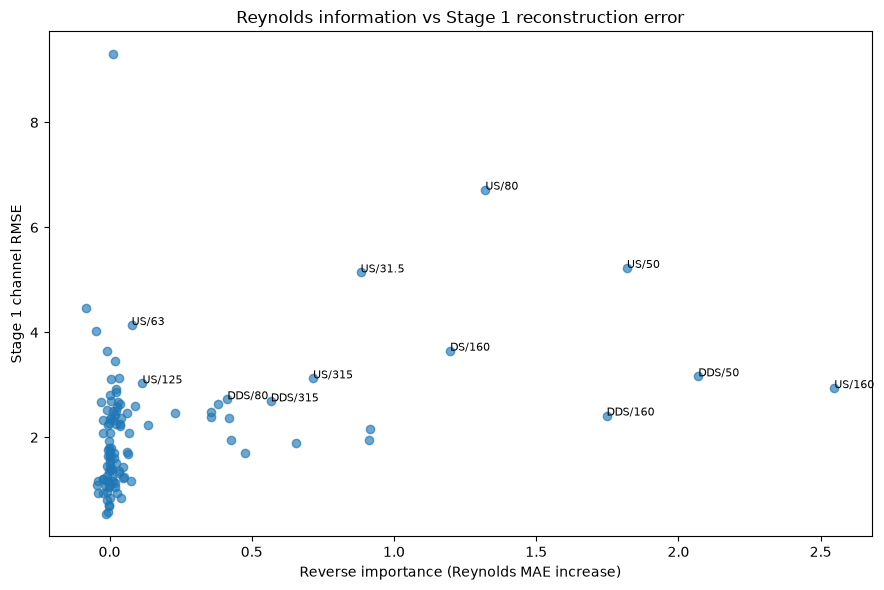

In [5]:
IMP_PATH=ROOT/'results'/'bidirectional_reynolds'/'reverse_grouped_importance.csv'
if not IMP_PATH.exists():
    raise FileNotFoundError(f'Run bidirectional_reynolds_diagnostics.ipynb first to generate {IMP_PATH}')
imp=pd.read_csv(IMP_PATH)
imp=imp.loc[imp.scope=='probe_frequency',['probe','frequency','importance']]
expected={(p,float(f)) for p in PROBES for f in val['freqs']}
assert set(zip(imp.probe,imp.frequency))==expected, 'Importance channels do not match evaluation spectra'
rows=[]
for pi,p in enumerate(PROBES):
    for fi,f in enumerate(val['freqs']):
        e=residual[:,pi,fi]
        rows.append(dict(probe=p,frequency=float(f),n=len(e),signed_bias=float(e.mean()),MAE=float(np.abs(e).mean()),RMSE=float(np.sqrt(np.mean(e**2)))))
ch=pd.DataFrame(rows).merge(imp,on=['probe','frequency'],validate='one_to_one')
# rank both importance and forward RMSE; use percentile ranks to avoid arbitrary unit mixing
ch['importance_pct']=ch.importance.rank(pct=True)
ch['error_pct']=ch.RMSE.rank(pct=True)
ch['joint_score']=ch.importance_pct*ch.error_pct
ch.sort_values('joint_score',ascending=False).to_csv(OUT/'frequency_priority.csv',index=False)
display(ch.sort_values('joint_score',ascending=False).head(20))
fig,ax=plt.subplots(figsize=(9,6));ax.scatter(ch.importance,ch.RMSE,alpha=.65)
for _,r in ch.nlargest(12,'joint_score').iterrows():ax.annotate(f"{r.probe}/{r.frequency:g}",(r.importance,r.RMSE),fontsize=8)
ax.set(xlabel='Reverse importance (Reynolds MAE increase)',ylabel='Stage 1 channel RMSE',title='Reynolds information vs Stage 1 reconstruction error');fig.tight_layout();fig.savefig(OUT/'importance_vs_stage1_error.png',dpi=170);plt.show()


## 3. Residuals versus Reynolds, ramps, and experimental time
Use time in elapsed minutes, Reynolds quintiles, and a ramp indicator based on a 15-s rolling average absolute Reynolds increment. The threshold is configurable and must be checked against actual sampling. These variables may be confounded; compare **within Reynolds bins** to reduce obvious mixing, without claiming identification. Report both signed bias and absolute error.

Ramp counts: {False: 3833, True: 3734} corr(Re,elapsed): -0.5665381760745313


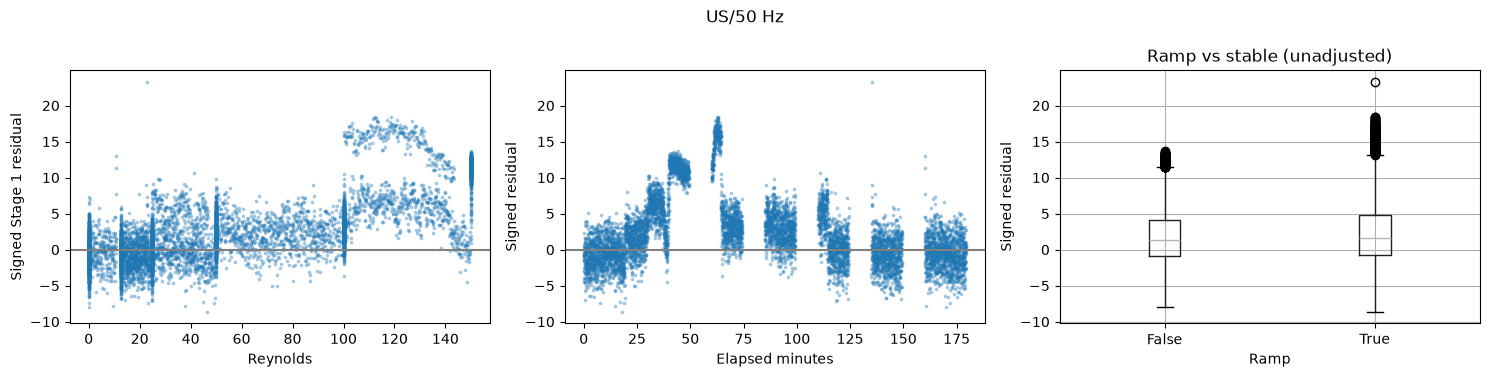

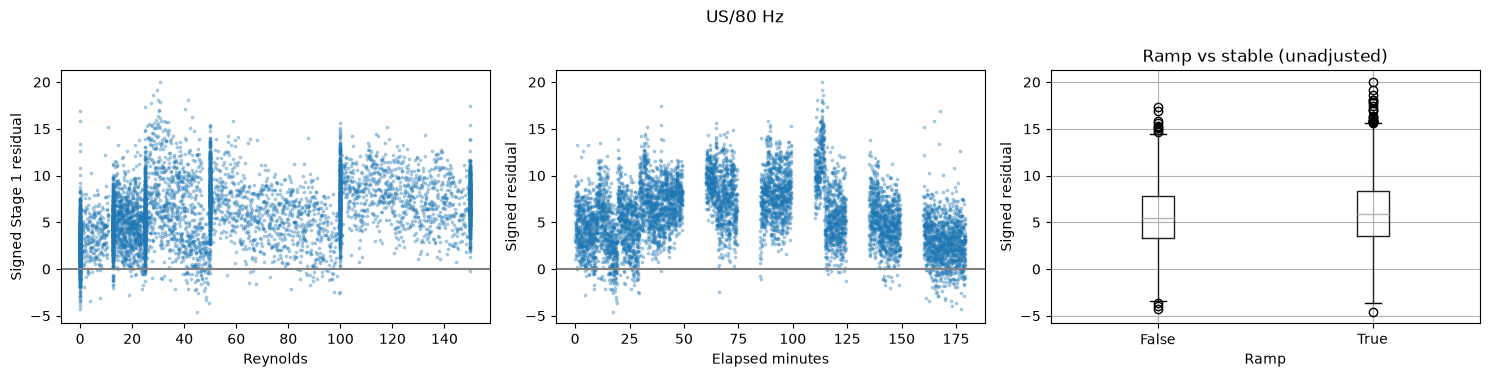

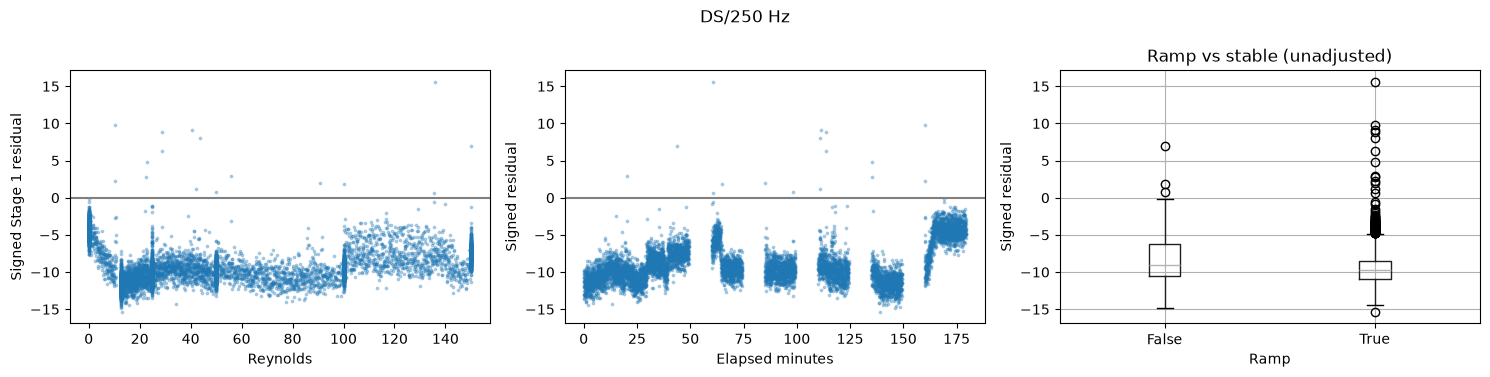

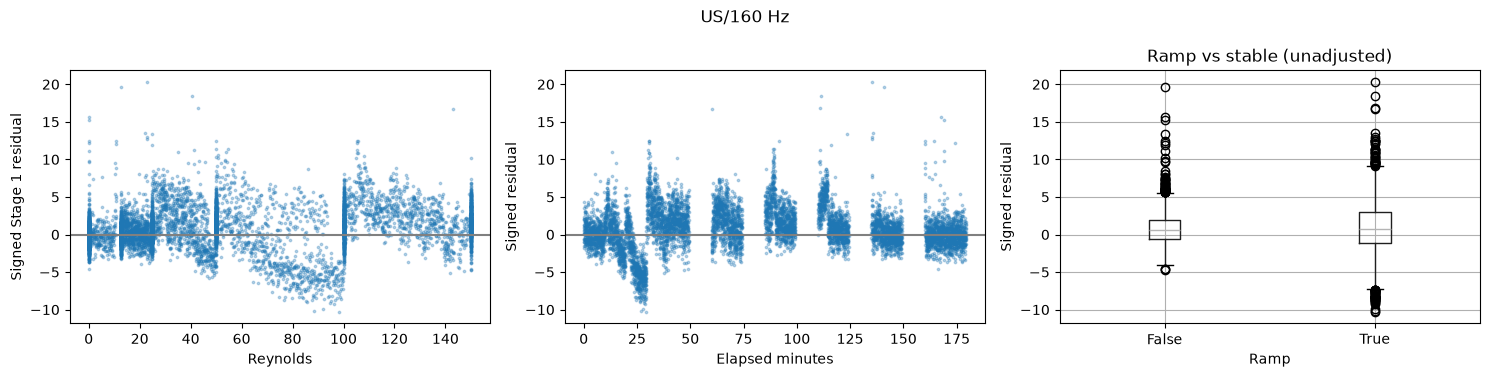

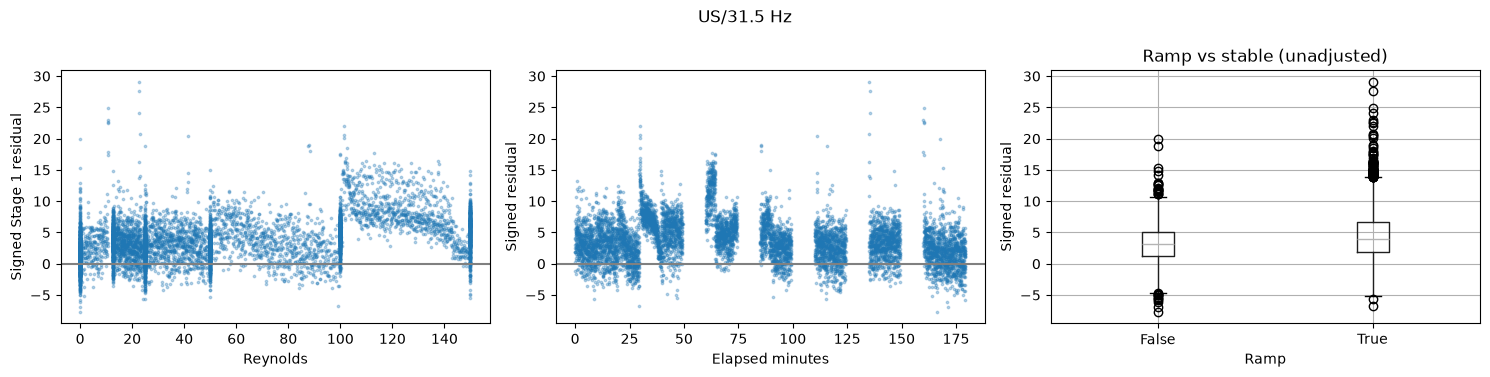

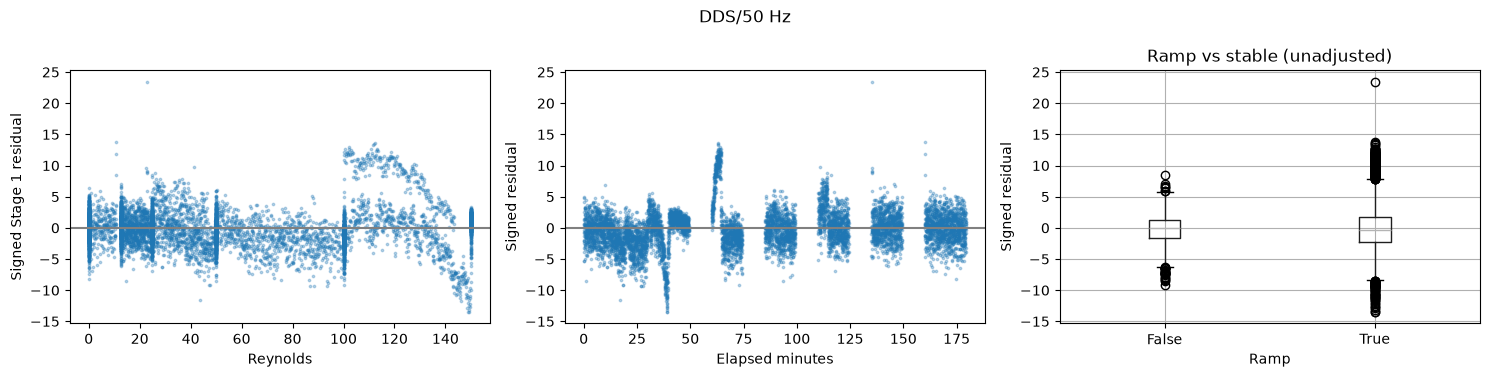

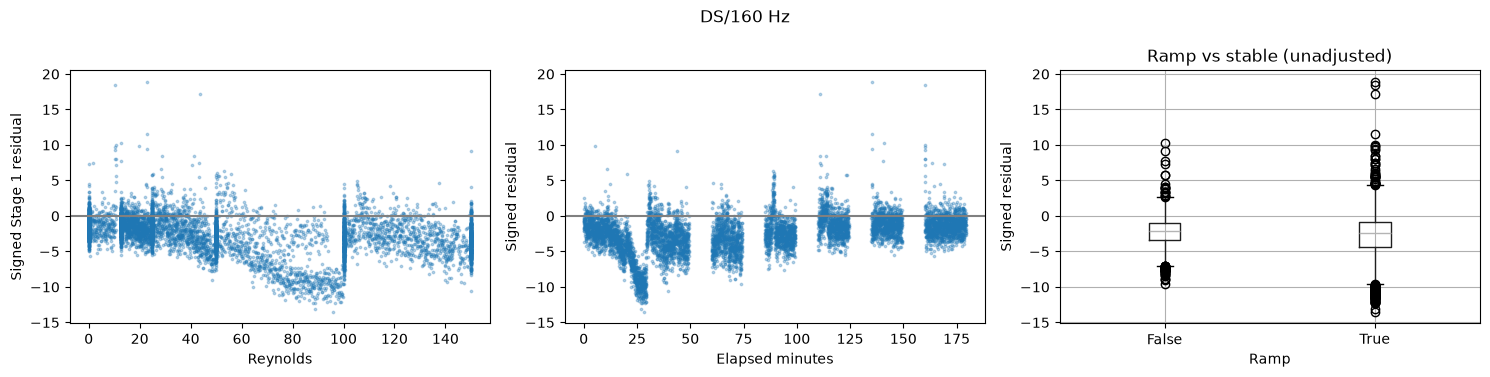

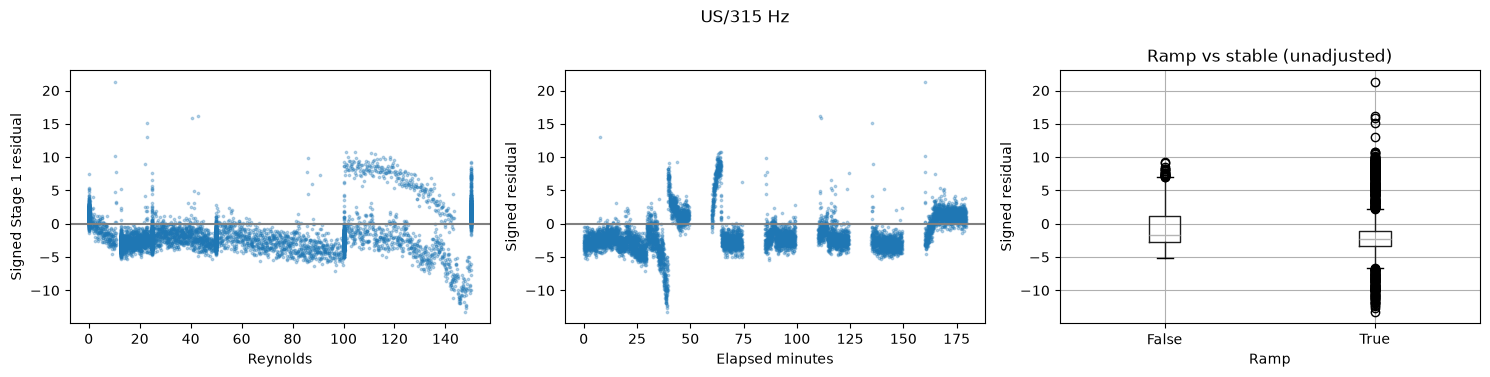

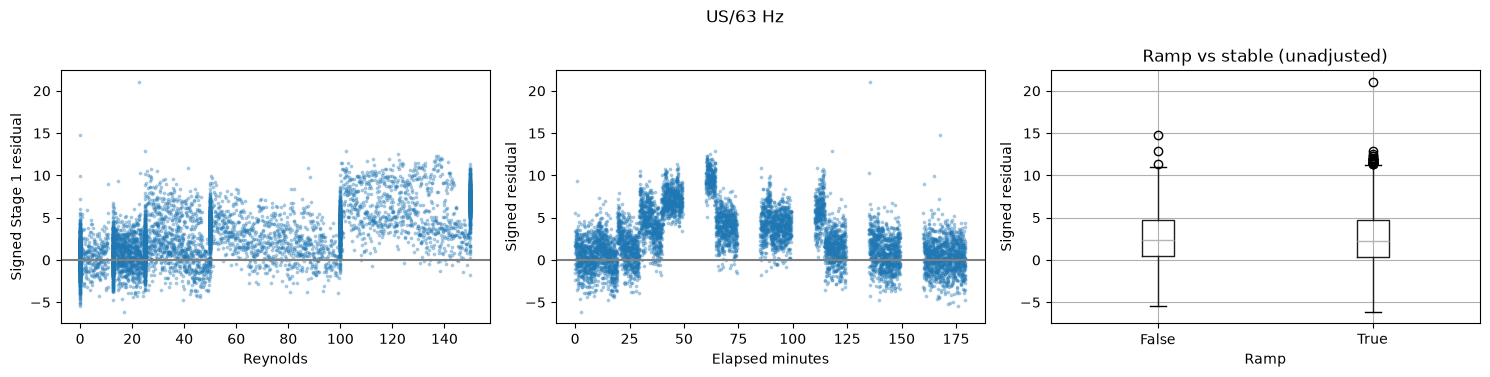

,probe,frequency,Re_bin,ramp,n,bias,MAE
0,US,50.0,"(-0.001, 12.5]",False,1485,-0.668666,1.921806
1,US,50.0,"(-0.001, 12.5]",True,277,-0.143868,1.868309
2,US,50.0,"(12.5, 25.0]",False,588,-0.104605,1.783758
3,US,50.0,"(12.5, 25.0]",True,835,-0.682923,1.931818
4,US,50.0,"(25.0, 50.0]",False,586,2.488611,2.765248
5,US,50.0,"(25.0, 50.0]",True,875,1.142780,2.801106
6,US,50.0,"(50.0, 100.0]",False,586,3.121563,3.207480
7,US,50.0,"(50.0, 100.0]",True,875,2.306637,2.712388
8,US,50.0,"(100.0, 150.0]",False,588,11.077992,11.077992
9,US,50.0,"(100.0, 150.0]",True,872,8.085756,8.143496


In [6]:
df=pd.DataFrame({'endpoint':idx_val,'datetime':pd.to_datetime(val['time'][idx_val]),'Re':y_re})
df['elapsed_min']=(df.datetime-df.datetime.iloc[0]).dt.total_seconds()/60
if not df.elapsed_min.is_monotonic_increasing: raise ValueError('Time must be monotonic')
delta=np.abs(np.diff(val['Re'],prepend=val['Re'][0]))
ramp_strength=pd.Series(delta).rolling(15,min_periods=1).mean().to_numpy()
RAMP_THRESHOLD=0.02
df['ramp_strength']=ramp_strength[idx_val]
df['ramp']=df.ramp_strength>RAMP_THRESHOLD
df['Re_bin']=pd.qcut(df.Re,q=RE_BINS,duplicates='drop')
print('Ramp counts:',df.ramp.value_counts().to_dict(),'corr(Re,elapsed):',df[['Re','elapsed_min']].corr().iloc[0,1])
priority=[('US',50.),('US',80.),('DS',250.),('US',160.)]
priority+= [(r.probe,float(r.frequency)) for _,r in ch.nlargest(8,'joint_score').iterrows()]
priority=list(dict.fromkeys(priority))
analysis_rows=[]
for p,f in priority:
    pi=PROBES.index(p); fi=int(np.argmin(abs(val['freqs']-f)))
    err=residual[:,pi,fi]
    d=df.copy();d['residual']=err;d['abs_residual']=np.abs(err)
    for group,part in d.groupby(['Re_bin','ramp'],observed=True):
        analysis_rows.append({'probe':p,'frequency':f,'Re_bin':str(group[0]),'ramp':bool(group[1]),'n':len(part),'bias':part.residual.mean(),'MAE':part.abs_residual.mean()})
    fig,axs=plt.subplots(1,3,figsize=(15,3.8))
    axs[0].scatter(d.Re,d.residual,s=3,alpha=.3);axs[0].axhline(0,color='gray');axs[0].set(xlabel='Reynolds',ylabel='Signed Stage 1 residual')
    axs[1].scatter(d.elapsed_min,d.residual,s=3,alpha=.3);axs[1].axhline(0,color='gray');axs[1].set(xlabel='Elapsed minutes',ylabel='Signed residual')
    d.boxplot(column='residual',by='ramp',ax=axs[2]);axs[2].set(xlabel='Ramp',ylabel='Signed residual');axs[2].set_title('Ramp vs stable (unadjusted)')
    fig.suptitle(f'{p}/{f:g} Hz');fig.tight_layout();fig.savefig(OUT/f'residual_{p}_{str(f).replace(".","p")}.png',dpi=145);plt.show()
bybin=pd.DataFrame(analysis_rows);bybin.to_csv(OUT/'residual_reynolds_ramp_bins.csv',index=False)
display(bybin[bybin.probe.eq('US') & bybin.frequency.isin([50.,80.])])


## 4. Stage 2 checkpoint and leak probabilities
Use the **original Stage 2 architecture**, loaded from its checkpoint. Stage 2 receives a 40-step sequence of Stage 1 residuals. Thus, Stage 1 predictions must first be computed for **every timestamp** from index 39 onward. No fabricated scores: if the Stage 2 checkpoint is missing or incompatible, stop with an actionable error.

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ProbeFrequencyUpdateBlock(nn.Module):
    def __init__(self, feat_dim, hidden_dim=64, dropout=0.1):
        super().__init__()
        self.feat_dim = feat_dim

        self.gate_mlp = nn.Sequential(
            nn.Linear(2 * feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

        self.out_dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(feat_dim)

    def forward(self, h_pre, return_stats=False):

        B_graph, P, D = h_pre.shape
        assert D == self.feat_dim, f"Expected feat_dim={self.feat_dim}, got {D}"

        hi = h_pre.unsqueeze(2).expand(B_graph, P, P, D)
        hj = h_pre.unsqueeze(1).expand(B_graph, P, P, D)

        diff = hj - hi
        abs_diff = torch.abs(diff)

        edge_feat = torch.cat([diff, abs_diff], dim=-1)
        gate = torch.sigmoid(self.gate_mlp(edge_feat))

        eye = torch.eye(P, device=h_pre.device).view(1, P, P, 1)
        gate = gate * (1.0 - eye)

        msg = diff * gate
        denom = gate.sum(dim=2).clamp_min(1e-6)
        agg = msg.sum(dim=2) / denom

        h_post = self.norm(self.out_dropout(agg))

        if return_stats:
            stats = {
                "gate_mean": gate.mean().detach(),
                "gate_matrix": gate.squeeze(-1).detach(),
                "agg_abs_mean": agg.abs().mean().detach(),
                "agg_norm": agg.norm(dim=-1).mean().detach(),
                "h_post_abs_mean": h_post.abs().mean().detach(),
                "h_post_norm": h_post.norm(dim=-1).mean().detach(),
            }
            return h_post, stats

        return h_post


class ResidualLSTMFrequencyGraphLeakNet(nn.Module):
    def __init__(
        self,
        Freq=27,
        hidden_dim=64,
        tf_hidden_dim=64,
        graph_hidden_dim=64,
        readout_hidden_dim=64,
        num_lstm_layers=1,
        dropout=0.1,
        weight_temperature=2.0,
    ):
        super().__init__()

        self.Freq = Freq
        self.hidden_dim = hidden_dim
        self.weight_temperature = weight_temperature


        # Per-probe temporal encoder
        self.lstm = nn.LSTM(
            input_size=Freq,
            hidden_size=hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=0.0 if num_lstm_layers == 1 else dropout
        )

        # Decode hidden temporal features back into frequency space.
        self.decode_freq = nn.Sequential(
            nn.Linear(hidden_dim, tf_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(tf_hidden_dim, Freq)
        )

        self.summary_dim = 3 * Freq

        self.freq_block_dim = 3
        self.readout_block_dim = 6
        self.readout_dim = self.readout_block_dim * Freq 

        # Frequency-wise graph block
        self.gnn = ProbeFrequencyUpdateBlock(
            feat_dim=self.freq_block_dim,
            hidden_dim=graph_hidden_dim,
            dropout=dropout
        )

        # Probe-frequency score head
        self.probe_freq_score_head = nn.Sequential(
            nn.Linear(self.readout_block_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )


        # Optional diagnostic per-probe heads
        self.probe_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.probe_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        # Global heads
        self.global_leak_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

        self.global_mag_head = nn.Sequential(
            nn.Linear(self.readout_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, readout_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(readout_hidden_dim, 1)
        )

    def _time_summary(self, x):

        x_mean = x.mean(dim=1)
        x_max = x.max(dim=1).values
        x_last = x[:, -1, :]

        return torch.cat([x_mean, x_max, x_last], dim=-1)

    def _reshape_summary_to_frequency_blocks(self, h_pre, B, P, Freq):
        h_pre_freq = h_pre.view(B, P, 3, Freq)
        h_pre_freq = h_pre_freq.permute(0, 1, 3, 2).contiguous()
        return h_pre_freq

    def _flatten_frequency_readout(self, h_readout_freq, B, P, Freq):

        h_readout = (
            h_readout_freq
            .permute(0, 1, 3, 2)    
            .contiguous()
            .view(B, P, 6 * Freq) 
        )
        return h_readout

    def _flatten_h_post_freq(self, h_post_freq, B, P, Freq):

        h_post = (
            h_post_freq
            .permute(0, 1, 3, 2)   
            .contiguous()
            .view(B, P, 3 * Freq)    
        )
        return h_post

    def _build_global_from_frequency_blocks(self, h_readout_freq):

        B, P, Freq, C = h_readout_freq.shape
        assert C == self.readout_block_dim, (
            f"Expected block dim={self.readout_block_dim}, got {C}"
        )

        # Score each probe-frequency block
        probe_freq_scores = self.probe_freq_score_head(h_readout_freq).squeeze(-1)

        # Independent sigmoid gates
        probe_freq_weights = torch.sigmoid(probe_freq_scores)

        # P-scaled weighted sum across probes
        h_global_freq = torch.sum(
            probe_freq_weights.unsqueeze(-1) * h_readout_freq,
            dim=1
        ) / P

        # Flatten back to (B, 6F)
        h_global = (
            h_global_freq
            .permute(0, 2, 1)
            .contiguous()
            .view(B, self.readout_block_dim * Freq)
        )

        # Diagnostic scalar per frequency
        h_global_scores = torch.sum(
            probe_freq_weights * probe_freq_scores,
            dim=1
        ) / P

        return (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        )

    def forward(
        self,
        residual_window,
        probe_coords=None,
        disable_gnn=False,
        return_gnn_stats=False,
    ):

        B, W, P, Freq = residual_window.shape
        assert Freq == self.Freq, f"Expected Freq={self.Freq}, got {Freq}"

        # Encode each probe independently through the LSTM
        x = residual_window.permute(0, 2, 1, 3).contiguous()
        x = x.view(B * P, W, Freq)

        lstm_out_raw, _ = self.lstm(x)    
        decoded_freq_raw = self.decode_freq(lstm_out_raw)  

        # Build mean / max / last time summary
        decoded_summary_raw = self._time_summary(decoded_freq_raw)
        h_pre = decoded_summary_raw.view(B, P, self.summary_dim)

        # Reshape into frequency-wise blocks
        h_pre_freq = self._reshape_summary_to_frequency_blocks(h_pre, B, P, Freq)

        # Graph each frequency across probes
        gnn_stats = None

        if not disable_gnn:
            h_for_gnn = h_pre_freq.permute(0, 2, 1, 3).contiguous()
            h_for_gnn = h_for_gnn.view(B * Freq, P, self.freq_block_dim)

            if return_gnn_stats:
                h_post_graph, gnn_stats = self.gnn(h_for_gnn, return_stats=True)
            else:
                h_post_graph = self.gnn(h_for_gnn)

            h_post_freq = h_post_graph.view(B, Freq, P, self.freq_block_dim)
            h_post_freq = h_post_freq.permute(0, 2, 1, 3).contiguous()
        else:
            h_post_freq = h_pre_freq

        # Flatten graph output for diagnostics
        h_post = self._flatten_h_post_freq(h_post_freq, B, P, Freq)

        # Build frequency-wise readout
        h_readout_freq = torch.cat([h_pre_freq, h_post_freq], dim=-1)

        # Flatten for optional diagnostic per-probe heads
        h_readout = self._flatten_frequency_readout(h_readout_freq, B, P, Freq)

        # Optional per-probe diagnostics
        probe_leak_logits = self.probe_leak_head(h_readout).squeeze(-1)
        probe_leak_probs = torch.sigmoid(probe_leak_logits)

        probe_mag_raw = self.probe_mag_head(h_readout).squeeze(-1)
        probe_mag_base = F.softplus(probe_mag_raw)

        # Build global vector from frequency-wise probe pooling
        (
            h_global,
            h_global_freq,
            probe_freq_scores,
            probe_freq_weights,
            h_global_scores,
        ) = self._build_global_from_frequency_blocks(h_readout_freq)

        # Global leak probability and magnitude
        leak_logit = self.global_leak_head(h_global).squeeze(-1)
        leak_prob = torch.sigmoid(leak_logit)

        mag_base = F.softplus(self.global_mag_head(h_global).squeeze(-1))

        magnitude = mag_base * leak_prob.detach()

        # Reshape LSTM outputs for diagnostics
        H = lstm_out_raw.shape[-1]

        lstm_out = (
            lstm_out_raw
            .view(B, P, W, H)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_freq = (
            decoded_freq_raw
            .view(B, P, W, Freq)
            .permute(0, 2, 1, 3)
            .contiguous()
        )

        decoded_summary = decoded_summary_raw.view(B, P, self.summary_dim)

        out = {
            # Final predictions
            "leak_logit": leak_logit,      # (B,)
            "leak_prob": leak_prob,        # (B,)
            "magnitude": magnitude,        # (B,)
            "mag_base": mag_base,          # (B,)

            # Main global representation
            "h_global": h_global,              # (B, 6F)
            "h_global_freq": h_global_freq,    # (B, F, 6)
            "h_global_scores": h_global_scores,# (B, F)

            # Frequency-wise graph / pooling diagnostics
            "h_pre_freq": h_pre_freq,                  # (B, P, F, 3)
            "h_post_freq": h_post_freq,                # (B, P, F, 3)
            "h_readout_freq": h_readout_freq,          # (B, P, F, 6)
            "probe_freq_scores": probe_freq_scores,    # (B, P, F)
            "probe_freq_weights": probe_freq_weights,  # (B, P, F)

            # Flattened diagnostics
            "h_pre": h_pre,                  # (B, P, 3F)
            "h_post": h_post,                # (B, P, 3F)
            "h_readout": h_readout,          # (B, P, 6F)

            # LSTM / decoded frequency diagnostics
            "lstm_out": lstm_out,                    # (B, W, P, H)
            "decoded_freq": decoded_freq,            # (B, W, P, F)
            "decoded_summary": decoded_summary,      # (B, P, 3F)

            # Optional per-probe diagnostic heads
            "probe_leak_logits": probe_leak_logits,  # (B, P)
            "probe_leak_probs": probe_leak_probs,    # (B, P)
            "probe_mag_base": probe_mag_base,        # (B, P)
        }

        if return_gnn_stats:
            out["gnn_stats"] = gnn_stats

        return out

In [8]:
stage2_path=ROOT/STAGE2_CHECKPOINT
if not stage2_path.exists(): raise FileNotFoundError(f'Stage 2 checkpoint missing: {stage2_path}; set STAGE2_CHECKPOINT in config')
state=safe_load(stage2_path)
if isinstance(state,dict) and 'model_state_dict' in state: state=state['model_state_dict']
if not isinstance(state,dict): raise ValueError('Stage 2 checkpoint must contain state_dict')
# Model hyperparameters from original GTvate_leak_detect notebook (not guessed)
stage2=ResidualLSTMFrequencyGraphLeakNet(Freq=27,hidden_dim=64,tf_hidden_dim=64,graph_hidden_dim=64,readout_hidden_dim=64,num_lstm_layers=1,dropout=.1).to(DEVICE)
stage2.load_state_dict(state,strict=True);stage2.eval()
print('Stage 2 loaded:',stage2_path)
all_idx=np.arange(W-1,len(val['Re']))
all_pred=batch_predict_forward(val,all_idx,batch=128)
full_residual=np.full_like(val['X'],np.nan,dtype=np.float32)
full_residual[all_idx]=val['X'][all_idx]-all_pred
# The residual window at t covers t-39..t; baseline at t-39 uses Reynolds history back to t-78.
valid_end=np.arange(2*(W-1),len(val['Re']))
# Only windows with no leak during the entire 79-s receptive field qualify as strictly healthy.
healthy=np.array([not np.any(val['leak'][t-2*(W-1):t+1]!=0) for t in valid_end])
healthy_end=valid_end[healthy]
if not len(healthy_end):raise ValueError('No fully healthy Stage 2 evaluation windows')
coords=torch.tensor([COORDS[val['run']][p] for p in PROBES],dtype=torch.float32,device=DEVICE)
probs=[]
with torch.no_grad():
    for start in range(0,len(healthy_end),128):
        ids=healthy_end[start:start+128]
        rw=np.stack([full_residual[t-W+1:t+1] for t in ids])/S_SCALE
        assert np.isfinite(rw).all()
        cc=coords.unsqueeze(0).expand(len(ids),-1,-1)
        probs.extend(stage2(torch.from_numpy(rw).to(DEVICE),cc)['leak_prob'].cpu().numpy().tolist())
alarms=pd.DataFrame({'endpoint':healthy_end,'datetime':pd.to_datetime(val['time'][healthy_end]),'Re':val['Re'][healthy_end], 'leak_prob':probs})
alarms['false_alarm']=alarms.leak_prob>=STAGE2_THRESHOLD
alarms.to_csv(OUT/'stage2_healthy_predictions.csv',index=False)
print(f'Healthy Stage 2 windows: {len(alarms)}; false-alarm windows: {alarms.false_alarm.sum()} at threshold {STAGE2_THRESHOLD}')


Stage 2 loaded: /home/ubuntu/notebooks/Leak_Detection/models/leak_detect_residual.pt
Healthy Stage 2 windows: 7333; false-alarm windows: 422 at threshold 0.5


## 5. Do residual patterns precede false-alarm *onsets*?
Define onset as the first alarm after a nonalarm among consecutive eligible endpoints; gaps break episodes. For each onset, examine preceding healthy windows **excluding the onset itself**, compare with healthy non-alarm reference windows, and report sample sizes. Avoid treating consecutive windows as independent events. This is an exploratory association; differences in Reynolds and time may confound comparisons.

Distinct false-alarm onsets: 41 preceding windows: 593 reference windows: 6482


,probe,frequency,n_onsets,n_pre_windows,n_reference_windows,pre_signed_bias,reference_signed_bias,pre_MAE,reference_MAE,pre_minus_reference_MAE
1,US,80.0,41,593,6482,6.794021,5.645682,6.823177,5.717500,1.105678
2,DS,250.0,41,593,6482,-9.877009,-8.786393,9.877009,8.805669,1.071341
8,US,63.0,41,593,6482,3.220765,2.566621,3.521258,3.128817,0.392441
4,US,31.5,41,593,6482,4.216892,3.598466,4.359690,3.988497,0.371193
3,US,160.0,41,593,6482,1.605368,0.614065,2.206819,2.108422,0.098397
5,DDS,50.0,41,593,6482,-0.103071,-0.219044,2.093518,2.334792,-0.241275
7,US,315.0,41,593,6482,-2.158475,-1.267835,2.344377,2.619934,-0.275558
0,US,50.0,41,593,6482,2.460469,2.370147,3.350944,3.720774,-0.369830
6,DS,160.0,41,593,6482,-2.055918,-2.624409,2.471369,2.913232,-0.441863


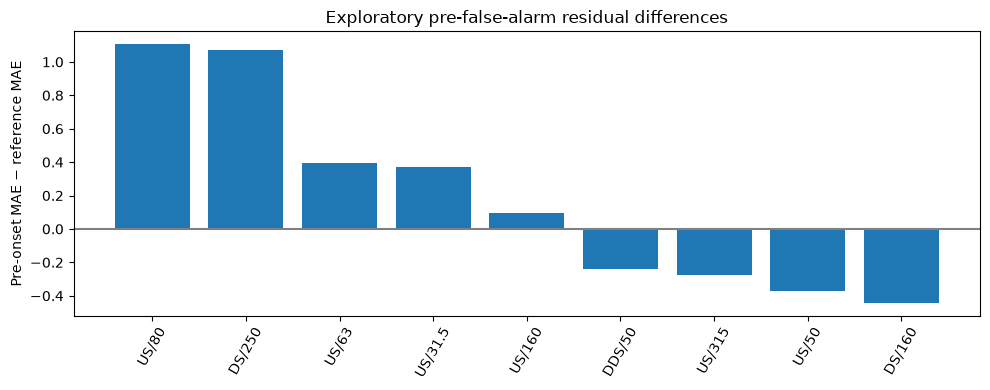

In [9]:
alarms['consecutive']=alarms.endpoint.diff().eq(1)
alarms['onset']=alarms.false_alarm & (~alarms.false_alarm.shift(fill_value=False) | ~alarms.consecutive)
onsets=alarms.loc[alarms.onset,'endpoint'].to_numpy(int)
# preceding endpoints must be present in fully healthy evaluation set; never cross gaps
valid_set=set(healthy_end.tolist()); preceding=set()
for t in onsets:
    for k in range(1,PRE_ALARM_LOOKBACK+1):
        if t-k not in valid_set:break
        preceding.add(t-k)
pre=np.asarray(sorted(preceding),dtype=int)
# Reference windows: not alarms, not preceding alarms, and not within lookback of any onset.
reference=np.asarray(sorted(valid_set-set(pre.tolist())-set(alarms.loc[alarms.false_alarm,'endpoint'].tolist())-set(onsets.tolist())),dtype=int)
print('Distinct false-alarm onsets:',len(onsets),'preceding windows:',len(pre),'reference windows:',len(reference))
if not len(onsets):
    print('No false-alarm onsets at this threshold; cannot test the pre-alarm hypothesis. Review threshold and data.')
else:
    results=[]
    for p,f in priority:
        pi=PROBES.index(p);fi=int(np.argmin(abs(val['freqs']-f)))
        a=full_residual[pre,pi,fi] if len(pre) else np.array([])
        b=full_residual[reference,pi,fi] if len(reference) else np.array([])
        results.append({'probe':p,'frequency':f,'n_onsets':len(onsets),'n_pre_windows':len(a),'n_reference_windows':len(b),'pre_signed_bias':np.mean(a) if len(a) else np.nan,'reference_signed_bias':np.mean(b) if len(b) else np.nan,'pre_MAE':np.abs(a).mean() if len(a) else np.nan,'reference_MAE':np.abs(b).mean() if len(b) else np.nan,'pre_minus_reference_MAE':np.abs(a).mean()-np.abs(b).mean() if len(a) and len(b) else np.nan})
    result=pd.DataFrame(results).sort_values('pre_minus_reference_MAE',ascending=False)
    result.to_csv(OUT/'pre_false_alarm_residual_comparison.csv',index=False)
    display(result)
    fig,ax=plt.subplots(figsize=(10,4));v=result.dropna(subset=['pre_minus_reference_MAE']);ax.bar([f'{p}/{f:g}' for p,f in zip(v.probe,v.frequency)],v.pre_minus_reference_MAE);ax.axhline(0,color='gray');ax.tick_params(axis='x',rotation=60);ax.set(ylabel='Pre-onset MAE − reference MAE',title='Exploratory pre-false-alarm residual differences');fig.tight_layout();fig.savefig(OUT/'pre_alarm_comparison.png',dpi=160);plt.show()
# Episode-centered event profiles, negative lags only, with no leak exposure
profiles=[]
for onset in onsets:
    for lag in range(-PRE_ALARM_LOOKBACK,1):
        t=onset+lag
        if t not in valid_set:continue
        row={'onset':onset,'lag':lag,'endpoint':t,'Re':float(val['Re'][t])}
        for p,f in [('US',50.),('US',80.)]:
            row[f'{p}_{f:g}_residual']=float(full_residual[t,PROBES.index(p),np.argmin(abs(val['freqs']-f))])
        profiles.append(row)
pd.DataFrame(profiles).to_csv(OUT/'false_alarm_onset_profiles.csv',index=False)


## 6. Interpretation checklist

- Prioritize US/50 and US/80 only if they jointly exhibit reverse-model importance, sizable Stage 1 errors, and an association with Stage 2 false-alarm onsets.
- Distinguish **signed bias** from **absolute error**; an error can be large but constant, or change with Reynolds and ramps.
- Check Reynolds–time confounding and the ramp threshold before interpreting trends.
- False-alarm counts are **overlapping windows**; the number of distinct onset episodes is the meaningful event count. Compare across multiple independent runs before statistical inference.
- **No false-alarm onset or missing checkpoint = no Stage 2 conclusion.**
- Results are associations; this notebook cannot establish that residuals *cause* Stage 2 false alarms.
